In [10]:
import sys
import os
from pathlib import Path

# Google Colab setup

if "google.colab" in sys.modules:

    repo_name = "jupyter-book-ioerdata"
    repo_url = "https://github.com/ioer-dresden/jupyter-book-ioerdata.git"

    # Start from Colab's main working directory.
    os.chdir("/content")

    # Clone the repository only if it is not already available.
    if not Path(repo_name).exists():
        !git clone -q {repo_url}

    # Move to the notebooks folder used by this training.
    os.chdir(Path("/content") / repo_name / "notebooks")

    # Install the packages required for this notebook.
    pyexec = sys.executable
    !../py/modules/pkginstall.sh "{pyexec}" geopandas matplotlib requests tqdm

    # Confirm that the Colab setup is complete.
    print("✓ Colab environment ready!")
    print("Working directory:")
    print(Path.cwd())

In [13]:
# Import the tools used in this notebook
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from time import perf_counter
from IPython.display import display
from matplotlib.patches import Rectangle
from tqdm.notebook import tqdm

print("Libraries Installed!")

Libraries Installed!


# 🏆 Final Mission 

```{admonition} Tell the Data Story
:class: tip

You have followed the data from download to analysis.

Now your task is to bring the evidence together and answer:

> **What does the data tell us about urban forest structure in Berlin?**

To close the case, you will:

- 🧩 connect the evidence
- 📊 select the strongest findings
- 🗺️ combine statistical and spatial evidence
- 🧠 separate evidence from interpretation

🏅 **Final badge to unlock:** Urban Data Investigator


## 🧩 Reconstruct the investigation

Let's look at the trail of evidence you have built.

>Mission 1 → Retrieved the data  
Mission 2 → Inspected the replication package  
Mission 3 → Understood the variables  
Mission 4 → Discovered patterns  
Mission 5 → Created visual evidence  
Mission 6 → Located patterns across Berlin  
Mission 7 → Connected canopy structure with urban form  

Now we can turn these individual clues into a **data story**.

### ❓ Start with the question

A data story needs a clear question.

For our investigation:

> How does urban forest structure vary across Berlin?

This question is broad enough to bring together our canopy indicators, maps, and Local Climate Zone analysis.

<hr style="border: none; border-top: 8px solid #70a401;">

### 🌳 Evidence 1: Canopy is more than coverage

We investigated two related indicators:

- `chm_area` → how much area is covered by canopy
- `chm_volume` → the amount of 3D canopy structure

Our comparison showed an important point:

> **Similar amounts of canopy cover do not necessarily mean similar 3D vegetation structure.**

The vertical dimension adds information that canopy area alone cannot provide.

```{admonition} 🔍 Evidence check
:class: note

Why might two grid cells with similar canopy area have different canopy volumes?

🌳 Think about the **height and vertical structure** of the vegetation.

<hr style="border: none; border-top: 8px solid #70a401;">

### 🗺️ Evidence 2: Location matters

Mapping the indicators added something that tables and charts could not show:

**where the differences occur.**

The canopy-height map revealed that urban forest structure varies spatially across the Berlin study area.

This transformed a statistical pattern into **spatial evidence**.

🌳 Final Mission: Berlin Canopy Height
📂 Output directory: /home/jovyan/work/jupyter-book-ioerdata/notebooks/outputs/final_mission
⏳ Loading spatial data (this may take a moment)...


/opt/conda/envs/worker_env/lib/python3.12/site-packages/pyogrio/raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D MultiPolygon' is converted to 'MultiPolygon Z'
  return ogr_read(


✅ Data loaded: 90,530 grid cells
⏱️ Elapsed: 0.2 seconds
⏳ Calculating canopy height...
✅ Calculation complete (0.2 seconds)
⏳ Rendering map (may take 10–60 seconds for large datasets)...
⏳ Saving your mission map...
🎉 Mission completed successfully!
📍 Saved to: /home/jovyan/work/jupyter-book-ioerdata/notebooks/outputs/final_mission/berlin_canopy_height.png
⏱️ Total execution time: 11.5 seconds


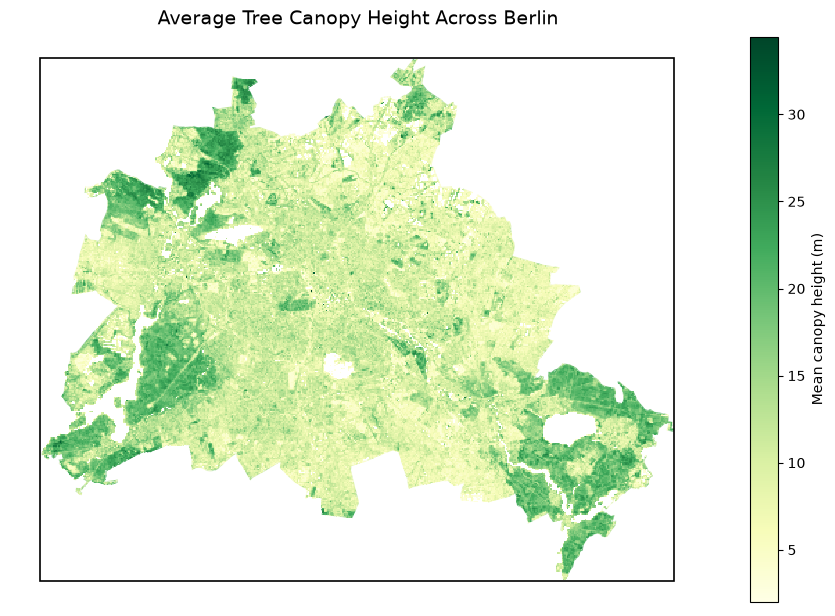

In [8]:
start = perf_counter()

input_file = Path(
    "data/g_raw/berlin_3D_canopy_stats_lczv3_grid100m_urau2021_epsg25833.gpkg"
)
output_dir = Path("outputs/final_mission")
output_dir.mkdir(parents=True, exist_ok=True)
output_file = output_dir / "berlin_canopy_height.png"

print("🌳 Final Mission: Berlin Canopy Height")
print(f"📂 Output directory: {output_dir.resolve()}")
print("⏳ Loading spatial data (this may take a moment)...", flush=True)

# Step 1: Read only necessary columns
berlin = gpd.read_file(
    input_file,
    columns=["chm_volume", "chm_area"],
    engine="pyogrio"
)

print(f"✅ Data loaded: {len(berlin):,} grid cells")
print(f"⏱️ Elapsed: {perf_counter() - start:.1f} seconds", flush=True)

# Step 2: Calculate mean canopy height
print("⏳ Calculating canopy height...", flush=True)

berlin["mean_canopy_height"] = np.divide(
    berlin["chm_volume"],
    berlin["chm_area"],
    out=np.full(len(berlin), np.nan),
    where=berlin["chm_area"].to_numpy() > 0
)

print(f"✅ Calculation complete ({perf_counter() - start:.1f} seconds)", flush=True)

# Step 3: Create visualization
print("⏳ Rendering map (may take 10–60 seconds for large datasets)...", flush=True)

fig, ax = plt.subplots(figsize=(9, 9))

berlin.plot(
    column="mean_canopy_height",
    cmap="YlGn",
    legend=True,
    linewidth=0,
    edgecolor="none",
    ax=ax,
    legend_kwds={
        "label": "Mean canopy height (m)",
        "shrink": 0.65
    },
    rasterized=True
)

# Fast rectangular study-area boundary
xmin, ymin, xmax, ymax = berlin.total_bounds
ax.add_patch(
    Rectangle(
        (xmin, ymin),
        xmax - xmin,
        ymax - ymin,
        fill=False,
        edgecolor="black",
        linewidth=1.2
    )
)

ax.set_title(
    "Average Tree Canopy Height Across Berlin",
    fontsize=14
)
ax.set_axis_off()

plt.tight_layout()

# Step 4: Save output
print("⏳ Saving your mission map...", flush=True)

fig.savefig(
    output_file,
    dpi=150,
    bbox_inches="tight"
)

print("🎉 Mission completed successfully!")
print(f"📍 Saved to: {output_file.resolve()}")
print(f"⏱️ Total execution time: {perf_counter() - start:.1f} seconds")

display(fig)
plt.close(fig)


In [12]:

#| tags: [remove-input]

from IPython.display import HTML, display
from pathlib import Path

# Find the Jupyter Book project root
project_dir = Path.cwd().resolve()

if not (project_dir / "_config.yml").exists():
    project_dir = project_dir.parent

# Save to the project's static folder
download_dir = project_dir / "_static" / "g_output"
download_dir.mkdir(parents=True, exist_ok=True)

output1_png = download_dir / "canopy_height_within_berlin.png"

fig.savefig(
    output1_png,
    dpi=300,
    bbox_inches="tight"
)

print(f"PNG saved to: {output1_png.resolve()}")

# Download button for Jupyter Book
display(
    HTML(
        """
<div style="margin: 1em 0;">
    <a href="../_static/g_output/canopy_height_within_berlin.png"
       download="canopy_height_within_berlin.png"
       style="display:inline-block;
              background-color:#2E7D32;
              color:white;
              padding:10px 14px;
              text-decoration:none;
              border-radius:6px;">
       ⬇️ Download PNG
    </a>
</div>
"""
    )
)


PNG saved to: /home/jovyan/work/jupyter-book-ioerdata/_static/g_output/canopy_height_within_berlin.png


<hr style="border: none; border-top: 8px solid #70a401;">

### 🏙️ Evidence 3: Urban context matters

In Mission 7, we connected canopy structure with **Local Climate Zones (LCZs)**.

The comparison showed that canopy characteristics can differ between urban environments.

But it also revealed variation **within** individual LCZ classes.

That gives us a more careful conclusion:

> Urban form and canopy structure appear to be related, but an LCZ class alone does not explain all variation in urban vegetation.

```{admonition} 🕵️ Investigator challenge
:class: note

You have three pieces of evidence:

🌳 **Structure** — canopy area and volume provide different information  
🗺️ **Space** — canopy structure varies across Berlin  
🏙️ **Urban context** — canopy patterns differ among and within LCZs  

Which piece of evidence do you think tells the strongest part of the story?

There is no single correct answer — a good interpretation depends on the question being asked.

<hr style="border: none; border-top: 8px solid #70a401;">

### 🧠 Build the data story

We can now connect the evidence into one concise interpretation:

>Urban forest structure varies considerably across Berlin. Canopy area describes the horizontal extent of vegetation, while canopy volume adds information about its vertical structure. Mapping these indicators reveals spatial differences across the city, and comparison with Local Climate Zones suggests that canopy characteristics also vary between different urban forms.

That is our data story.

>It connects the **question → evidence → spatial pattern → interpretation**.

### ⚠️ Know what the evidence cannot tell us

A responsible data story also recognises its limits.

Our analysis can identify **patterns and associations**, but it cannot automatically explain why they occur.

For example, differences in canopy structure could relate to:

>- urban form,
>- parks and land use,
>- planning history,
>- vegetation management,
>- or other factors not included in this analysis.

Further evidence would be needed to investigate these explanations.

```{tip}
A strong conclusion does not claim more than the data supports.

Use:

**“The data shows…”** for observed patterns.

Use:

**“This may suggest…”** when proposing a possible explanation.

<hr style="border: none; border-top: 8px solid #70a401;">

### 🔁 The reproducibility trail

There is one final piece of the investigation.

Someone else should be able to understand **where the evidence came from and how it was produced**.

Throughout these missions, you worked with:

>**ioerDATA dataset**  
↓  
**replication package**  
↓  
**GeoPackage**  
↓  
**Python analysis**  
↓  
**figures and maps**  
↓  
**interpretation**

This trail makes the analysis easier to inspect, reproduce, and extend.

### 🚀 Where could the investigation go next?

Closing this case does not mean the analysis has to end.

The same workflow could be extended to:

>- 🇳🇱 compare Berlin with Amsterdam
>- 🏢 investigate building volume alongside canopy structure
>- 🌳 explore individual Local Climate Zones in more detail
>- 🗺️ develop more advanced spatial analyses
>- 📊 reproduce additional results from the original study

The replication package gives you a starting point — not an endpoint.

```{raw} html
<div class="admonition tip" id="case-complete-box">
  <p class="admonition-title">🎉 Investigation Complete!</p>

  <h2>🏆 Urban Data Investigator</h2>

  <p>
    You followed the complete research-data journey — from finding a dataset
    to interpreting and communicating spatial evidence.
  </p>

  <ul>
    <li>✔ Research data retrieved</li>
    <li>✔ Replication package investigated</li>
    <li>✔ Indicators interpreted</li>
    <li>✔ Patterns analysed</li>
    <li>✔ Visual evidence created</li>
    <li>✔ Spatial patterns mapped</li>
    <li>✔ Analysis extended</li>
    <li>✔ Data story completed</li>
  </ul>

  <p><strong>Status:</strong> All missions complete 🎯</p>

  <button
    onclick="completeMission8()"
    style="
      padding: 12px 20px;
      font-weight: bold;
      border-radius: 6px;
      cursor: pointer;
    ">
    🏆 Close the Case
  </button>

  <p
    id="mission-8-complete-message"
    style="font-weight: bold; margin-top: 14px;">
  </p>

  <div id="celebration-area"></div>
</div>

<style>
#case-complete-box {
  position: relative;
  overflow: hidden;
}

.case-closed-animation {
  animation: casePulse 0.7s ease;
}

@keyframes casePulse {
  0%   { transform: scale(1); }
  50%  { transform: scale(1.02); }
  100% { transform: scale(1); }
}

.confetti {
  position: absolute;
  top: -20px;
  font-size: 22px;
  pointer-events: none;
  animation: confettiFall 1.8s ease-out forwards;
}

@keyframes confettiFall {
  0% {
    transform: translateY(0) rotate(0deg);
    opacity: 1;
  }

  100% {
    transform: translateY(320px) rotate(540deg);
    opacity: 0;
  }
}

.case-closed-text {
  font-size: 1.2rem;
  animation: caseTextPop 0.6s ease;
}

@keyframes caseTextPop {
  0% {
    transform: scale(0.8);
    opacity: 0;
  }

  70% {
    transform: scale(1.08);
  }

  100% {
    transform: scale(1);
    opacity: 1;
  }
}
</style>

<script>
function playCelebrationSound() {
  const AudioContext =
    window.AudioContext || window.webkitAudioContext;

  if (!AudioContext) return;

  const audioContext = new AudioContext();

  const notes = [523.25, 659.25, 783.99];

  notes.forEach((frequency, index) => {
    const oscillator = audioContext.createOscillator();
    const gain = audioContext.createGain();

    oscillator.type = "sine";
    oscillator.frequency.value = frequency;

    gain.gain.setValueAtTime(
      0.12,
      audioContext.currentTime + index * 0.12
    );

    gain.gain.exponentialRampToValueAtTime(
      0.001,
      audioContext.currentTime + index * 0.12 + 0.3
    );

    oscillator.connect(gain);
    gain.connect(audioContext.destination);

    oscillator.start(
      audioContext.currentTime + index * 0.12
    );

    oscillator.stop(
      audioContext.currentTime + index * 0.12 + 0.3
    );
  });
}

function launchConfetti() {
  const container =
    document.getElementById("case-complete-box");

  const symbols = ["🎉", "✨", "🎊", "⭐"];

  for (let i = 0; i < 18; i++) {
    const piece = document.createElement("span");

    piece.className = "confetti";
    piece.innerHTML =
      symbols[Math.floor(Math.random() * symbols.length)];

    piece.style.left =
      Math.random() * 95 + "%";

    piece.style.animationDelay =
      Math.random() * 0.4 + "s";

    container.appendChild(piece);

    setTimeout(() => {
      piece.remove();
    }, 2500);
  }
}

function completeMission8() {

  localStorage.setItem(
    "urban_data_mission_8_completed",
    "true"
  );

  localStorage.setItem(
    "urban_data_badge_8",
    "Urban Data Investigator"
  );

  localStorage.setItem(
    "urban_data_mission_8_completed_at",
    new Date().toISOString()
  );

  const box =
    document.getElementById("case-complete-box");

  const message =
    document.getElementById(
      "mission-8-complete-message"
    );

  message.innerHTML =
    '<span class="case-closed-text">🎉 Case closed! You completed the Urban Data Investigator journey.</span>';

  box.classList.remove("case-closed-animation");
  void box.offsetWidth;
  box.classList.add("case-closed-animation");

  launchConfetti();
  playCelebrationSound();
}
</script>

### 🎮 Mission Progress

🟢 Mission 1: Locate & Retrieve Data ✅  
🟢 Mission 2: Inspect the Package ✅  
🟢 Mission 3: Understand the Data ✅  
🟢 Mission 4: Generate Insights ✅  
🟢 Mission 5: Create Visual Evidence ✅  
🟢 Mission 6: Map the City ✅  
🟢 Mission 7: Extend the Analysis ✅  
🟢 **Final Mission: Tell the Data Story ← Current**

**Progress:** ▰▰▰▰▰▰▰▰ **8/8 Complete**
<hr style="border: none; border-top: 8px solid #70a401;">

### 🎉 Case Closed

You started with a dataset.

You finished with **evidence, maps, interpretation, and a reproducible research story**.

>🏆 **Urban Data Investigator journey complete.**

But every good investigation creates new questions.

**Where will you take the data next?**

<hr style="border: none; border-top: 8px solid #70a401;">